# Physical and biological response to wind event 

## Diatom response

Code reused from https://github.com/SalishSeaCast/analysis-junqi/blob/main/Analysis_Storm_Bio_Response/Report_D%26F_Section.ipynb.

In [2]:
# files

# Example: "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/" + "SalishSea_1d_20230301_20230331_grid_T.nc"


EXPERIMENTS_head = {
    "HRDPS2.5": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps2.5/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps2.5/" # Not available yet
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS1": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps1/"
            "SalishSea_1d_20230301_20230328"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps1/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps1/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "CaSR": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_CaSR/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_CaSR/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_CaSR/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS10": {
        "Mar": (
            "/ocean/jqiu/results/Flux/flux_00mar23_hrdps10/"
            "SalishSea_1d_20230301_20230331"
        ),
        "Jun": (
                    "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/" 
                    "SalishSea_1d_20230601_20230630"
        ),
        "Sep": (
                    "/ocean/jqiu/results/Flux/flux_00sep23_hrdps10/" 
                    "SalishSea_1d_20230901_20230930"
        ),
        "Dec": (
                    "/ocean/jqiu/results/Flux/flux_00dec23_hrdps10/" 
                    "SalishSea_1d_20231201_20231231"
        ),
    },
    "HRDPS2.5+CaSR_wind": {
            "Mar": (
                "/ocean/jqiu/results/Sensivity/CaSR_wind_HRDPS_else/"
                "SalishSea_1d_20230301_20230331"
        ),
    },
    "CaSR+HRDPS2.5_wind": {
                "Mar": (
                    "/ocean/jqiu/results/Sensivity/HRDPS_wind_CaSR_else/"
                    "SalishSea_1d_20230301_20230331"
            ),
    },
}


EXPERIMENTS_tail = {
    'Physical': '_grid_T.nc',
    'Biological': '_biol_T.nc',
    'Velocity_u': '_grid_U.nc',
    'Velocity_v': '_grid_V.nc',
    'Chemical': '_chem_T.nc'
}

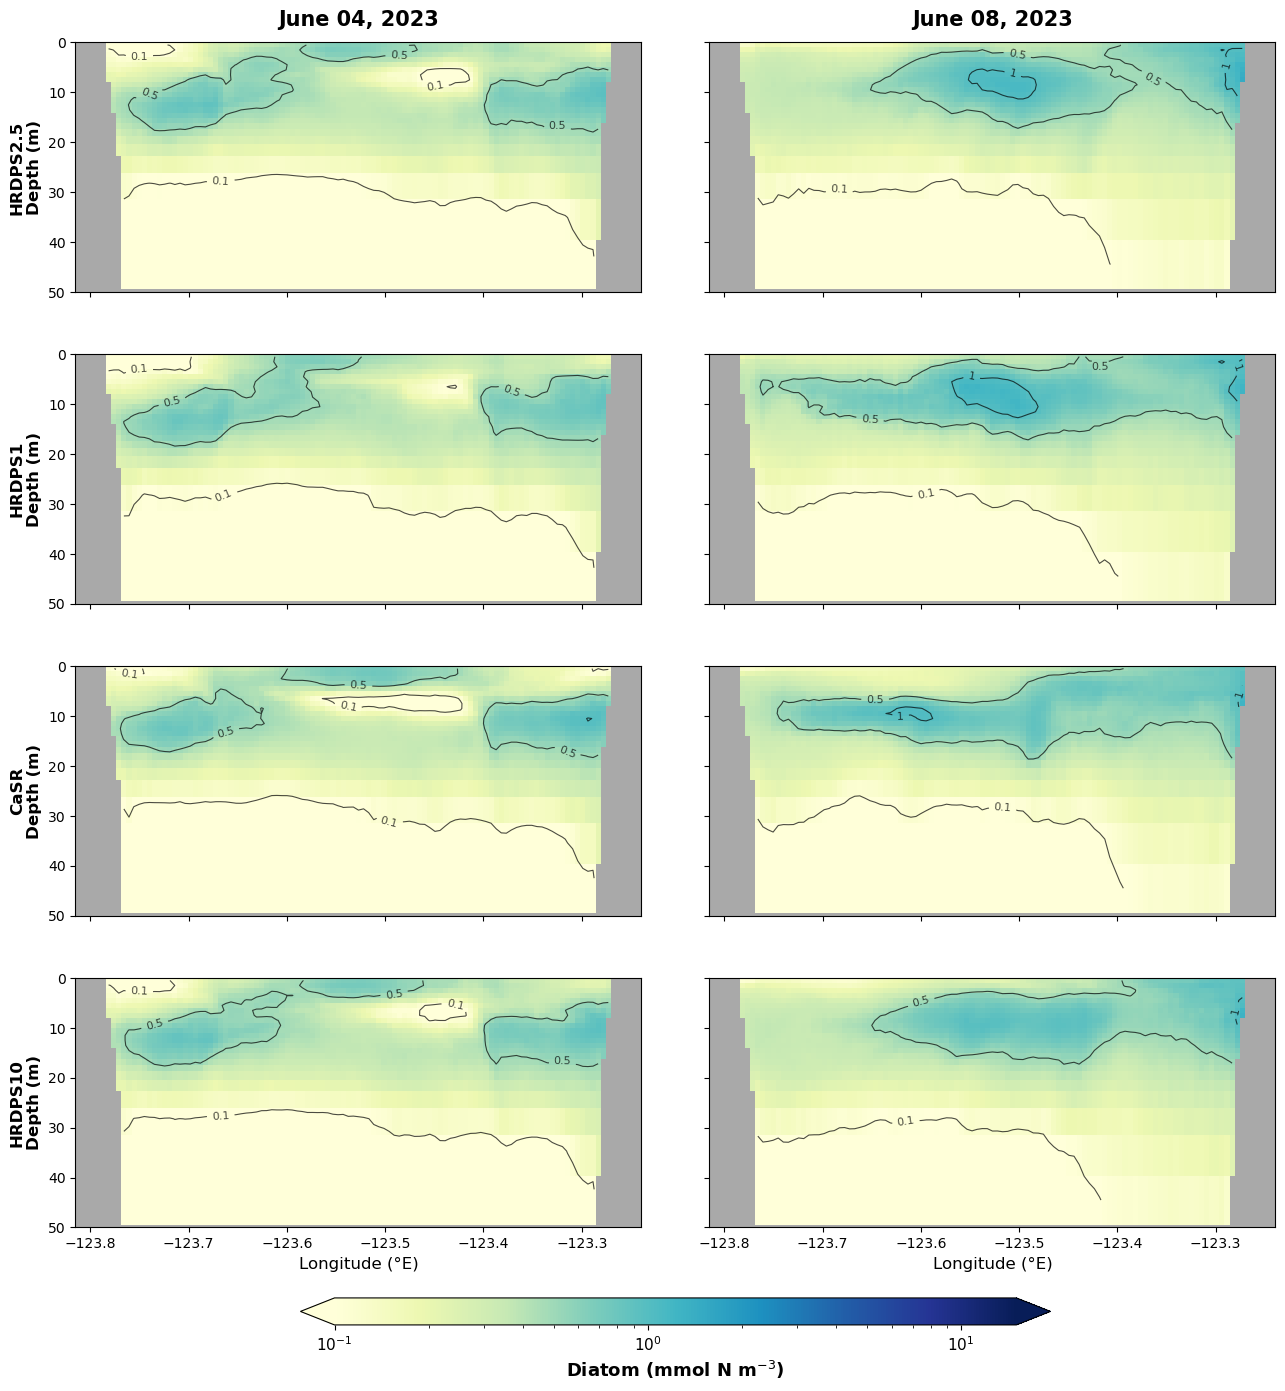

In [4]:

# Bio_Section_Plot_2023_CentralSoG.py
# 2023 June 4 and June 8
# Diatom vertical sections at Central SoG
# 4 experiments x 2 dates

import os
import datetime
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# configure

EXPERIMENTS = {
    "HRDPS2.5": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS1": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/",
        "SalishSea_1d_20230601_20230630"
    ),
    "CaSR": (
        "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS10": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/",
        "SalishSea_1d_20230601_20230630"
    ),
}

DATES = [
    datetime.date(2023, 6, 4),
    datetime.date(2023, 6, 8)
]

# Central Strait of Georgia
Y_CENTER = 475
X_CENTER = 275

# East-West section
LEFT_OFFSET = 50
RIGHT_OFFSET = 60

DEPTH_LIMIT = 50

# Diatom color scale
VMIN = 0.1
VMAX = 15
CONTOUR_LEVELS = [0.1, 0.5, 1, 2, 5, 10]

CMAP = "YlGnBu"

OUTPUT_FILE = "Diatom_CentralSoG_June2023_4x2.png"


# load

def load_diatom_section(experiment, date_obj):

    base_dir, file_head = EXPERIMENTS[experiment]

    file_path = os.path.join(
        base_dir,
        file_head + "_biol_T.nc"
    )

    if not os.path.exists(file_path):
        print(f"File missing: {file_path}")
        return None

    with nc.Dataset(file_path, "r") as ds:

        # Time coordinate
        time_var = ds.variables["time_counter"]

        times = nc.num2date(
            time_var[:],
            units=time_var.units,
            calendar=getattr(time_var, "calendar", "standard")
        )

        # Match target date
        time_idx = [
            i for i, t in enumerate(times)
            if (t.year, t.month, t.day) ==
               (date_obj.year, date_obj.month, date_obj.day)
        ]

        if len(time_idx) == 0:
            print(f"Date missing: {experiment}, {date_obj}")
            return None

        tidx = time_idx[0]

        # Depth
        depths = np.asarray(ds.variables["deptht"][:])

        z_indices = np.where(depths <= DEPTH_LIMIT)[0]

        if len(z_indices) == 0:
            raise ValueError("No depth levels within depth limit")

        nz = len(z_indices)

        # Longitude and latitude
        lon_2d = np.ma.filled(
            ds.variables["nav_lon"][:], np.nan
        )

        lat_2d = np.ma.filled(
            ds.variables["nav_lat"][:], np.nan
        )

        # Section range
        nx = lon_2d.shape[1]

        x_start = max(0, X_CENTER - LEFT_OFFSET)
        x_end = min(nx, X_CENTER + RIGHT_OFFSET + 1)

        x_slice = slice(x_start, x_end)

        # Extract diatoms
        diatom = ds.variables["diatoms"][
            tidx,
            :nz,
            Y_CENTER,
            x_slice
        ]

        diatom = np.ma.masked_invalid(diatom)
        diatom = np.ma.masked_less_equal(diatom, 0)

        lon_sec = lon_2d[Y_CENTER, x_slice]
        lat_sec = lat_2d[Y_CENTER, x_slice]

    return diatom, lon_sec, lat_sec, depths[:nz]


# visualize

def plot_section(ax, diatom, lon, depths):

    ax.set_facecolor("darkgray")

    X, Z = np.meshgrid(lon, depths)

    cf = ax.pcolormesh(
        X,
        Z,
        diatom,
        norm=LogNorm(vmin=VMIN, vmax=VMAX),
        cmap=CMAP,
        shading="auto"
    )

    # Contours
    valid = np.ma.compressed(diatom)

    if valid.size > 0:
        levels = [
            lev for lev in CONTOUR_LEVELS
            if valid.min() < lev < valid.max()
        ]

        if levels:
            cs = ax.contour(
                X,
                Z,
                diatom,
                levels=levels,
                colors="black",
                linewidths=0.8,
                alpha=0.7
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=8,
                fmt="%g"
            )

    # Depth increases downward
    ax.set_ylim(DEPTH_LIMIT, 0)

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    return cf




def main():

    models = list(EXPERIMENTS.keys())

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(15, 15),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.90,
        top=0.92,
        bottom=0.13,
        hspace=0.25,
        wspace=0.12
    )

    cf_last = None

    for row, model in enumerate(models):

        for col, date_obj in enumerate(DATES):

            ax = axes[row, col]

            result = load_diatom_section(
                model,
                date_obj
            )

            if result is None:
                ax.text(
                    0.5, 0.5,
                    "Data Missing",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )
                continue

            diatom, lon, lat, depths = result

            cf = plot_section(
                ax,
                diatom,
                lon,
                depths
            )

            cf_last = cf

            # Column titles
            if row == 0:
                ax.set_title(
                    date_obj.strftime("%B %d, %Y"),
                    fontsize=15,
                    fontweight="bold",
                    pad=12
                )

            # Model labels
            if col == 0:
                ax.set_ylabel(
                    f"{model}\nDepth (m)",
                    fontsize=12,
                    fontweight="bold"
                )

            # Bottom X labels
            if row == 3:
                ax.set_xlabel(
                    "Longitude (°E)",
                    fontsize=12
                )

    # colorbar

    if cf_last is not None:

        cbar_ax = fig.add_axes([
            0.25, 0.065, 0.50, 0.018
        ])

        cbar = fig.colorbar(
            cf_last,
            cax=cbar_ax,
            orientation="horizontal",
            extend="both"
        )

        cbar.set_label(
            "Diatom (mmol N m$^{-3}$)",
            fontsize=13,
            fontweight="bold"
        )

        cbar.ax.tick_params(labelsize=11)



    plt.show()




if __name__ == "__main__":
    main()


## Salinity response

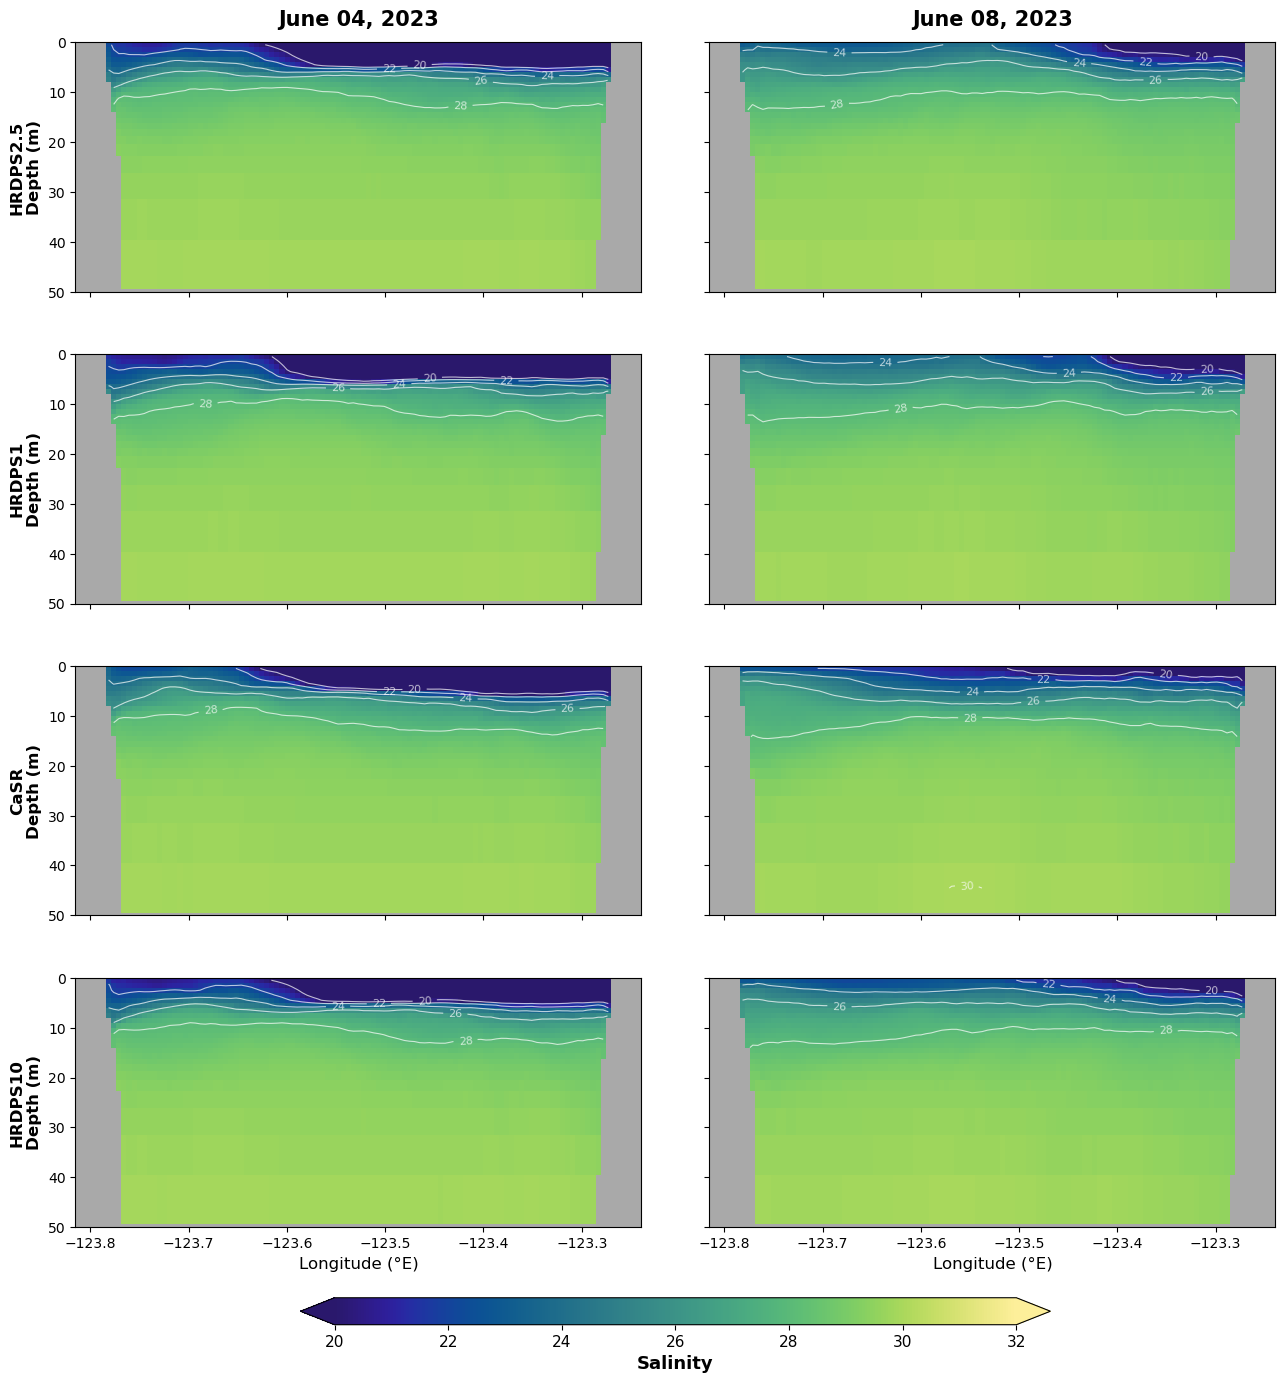

In [9]:

# Salinity_Section_Plot_2023_CentralSoG.py
# 2023 June 4 and June 8
# Diatom vertical sections at Central SoG
# 4 experiments x 2 dates

import os
import datetime
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import cmocean
from matplotlib.colors import Normalize

# configure

EXPERIMENTS = {
    "HRDPS2.5": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS1": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/",
        "SalishSea_1d_20230601_20230630"
    ),
    "CaSR": (
        "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS10": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/",
        "SalishSea_1d_20230601_20230630"
    ),
}

DATES = [
    datetime.date(2023, 6, 4),
    datetime.date(2023, 6, 8)
]

# Central Strait of Georgia
Y_CENTER = 475
X_CENTER = 275

# East-West section
LEFT_OFFSET = 50
RIGHT_OFFSET = 60

DEPTH_LIMIT = 50

# Diatom color scale
VMIN = 20
VMAX = 32
# CONTOUR_LEVELS = [0.1, 0.5, 1, 2, 5, 10]
CONTOUR_LEVELS = [20, 22, 24, 26, 28, 30, 32]

CMAP = cmocean.cm.haline


# load

def load_salinity_section(experiment, date_obj):

    base_dir, file_head = EXPERIMENTS[experiment]

    file_path = os.path.join(
        base_dir,
        file_head + "_grid_T.nc"
    )

    if not os.path.exists(file_path):
        print(f"File missing: {file_path}")
        return None

    with nc.Dataset(file_path, "r") as ds:

        # Time coordinate
        time_var = ds.variables["time_counter"]

        times = nc.num2date(
            time_var[:],
            units=time_var.units,
            calendar=getattr(time_var, "calendar", "standard")
        )

        # Match target date
        time_idx = [
            i for i, t in enumerate(times)
            if (t.year, t.month, t.day) ==
               (date_obj.year, date_obj.month, date_obj.day)
        ]

        if len(time_idx) == 0:
            print(f"Date missing: {experiment}, {date_obj}")
            return None

        tidx = time_idx[0]

        # Depth
        depths = np.asarray(ds.variables["deptht"][:])

        z_indices = np.where(depths <= DEPTH_LIMIT)[0]

        if len(z_indices) == 0:
            raise ValueError("No depth levels within depth limit")

        nz = len(z_indices)

        # Longitude and latitude
        lon_2d = np.ma.filled(
            ds.variables["nav_lon"][:], np.nan
        )

        lat_2d = np.ma.filled(
            ds.variables["nav_lat"][:], np.nan
        )

        # Section range
        nx = lon_2d.shape[1]

        x_start = max(0, X_CENTER - LEFT_OFFSET)
        x_end = min(nx, X_CENTER + RIGHT_OFFSET + 1)

        x_slice = slice(x_start, x_end)

        # Extract salinity
        diatom = ds.variables["vosaline"][
            tidx,
            :nz,
            Y_CENTER,
            x_slice
        ]

        diatom = np.ma.masked_invalid(diatom)
        diatom = np.ma.masked_less_equal(diatom, 0)

        lon_sec = lon_2d[Y_CENTER, x_slice]
        lat_sec = lat_2d[Y_CENTER, x_slice]

    return diatom, lon_sec, lat_sec, depths[:nz]


# visualize

def plot_section(ax, diatom, lon, depths):

    ax.set_facecolor("darkgray")

    X, Z = np.meshgrid(lon, depths)

    cf = ax.pcolormesh(
        X,
        Z,
        diatom,
        #norm=LogNorm(vmin=VMIN, vmax=VMAX),
        norm=Normalize(vmin=VMIN, vmax=VMAX),
        cmap=CMAP,
        shading="auto"
    )

    # Contours
    valid = np.ma.compressed(diatom)

    if valid.size > 0:
        levels = [
            lev for lev in CONTOUR_LEVELS
            if valid.min() < lev < valid.max()
        ]

        if levels:
            cs = ax.contour(
                X,
                Z,
                diatom,
                levels=levels,
                colors="white",
                linewidths=0.8,
                alpha=0.7
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=8,
                fmt="%g"
            )

    # Depth increases downward
    ax.set_ylim(DEPTH_LIMIT, 0)

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    return cf




def main():

    models = list(EXPERIMENTS.keys())

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(15, 15),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.90,
        top=0.92,
        bottom=0.13,
        hspace=0.25,
        wspace=0.12
    )

    cf_last = None

    for row, model in enumerate(models):

        for col, date_obj in enumerate(DATES):

            ax = axes[row, col]

            result = load_salinity_section(
                model,
                date_obj
            )

            if result is None:
                ax.text(
                    0.5, 0.5,
                    "Data Missing",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )
                continue

            diatom, lon, lat, depths = result

            cf = plot_section(
                ax,
                diatom,
                lon,
                depths
            )

            cf_last = cf

            # Column titles
            if row == 0:
                ax.set_title(
                    date_obj.strftime("%B %d, %Y"),
                    fontsize=15,
                    fontweight="bold",
                    pad=12
                )

            # Model labels
            if col == 0:
                ax.set_ylabel(
                    f"{model}\nDepth (m)",
                    fontsize=12,
                    fontweight="bold"
                )

            # Bottom X labels
            if row == 3:
                ax.set_xlabel(
                    "Longitude (°E)",
                    fontsize=12
                )

    # colorbar

    if cf_last is not None:

        cbar_ax = fig.add_axes([
            0.25, 0.065, 0.50, 0.018
        ])

        cbar = fig.colorbar(
            cf_last,
            cax=cbar_ax,
            orientation="horizontal",
            extend="both"
        )

        cbar.set_label(
            "Salinity",
            fontsize=13,
            fontweight="bold"
        )

        cbar.ax.tick_params(labelsize=11)



    plt.show()




if __name__ == "__main__":
    main()

**What happened to the surface fresh water?** Wind towards South pushed Fraser River fresh water south, preventing it from taking up the surface.

## Change the location

It seems that Central SoG is significantly influenced by Fraser River Plum. Now try another place.

### Map

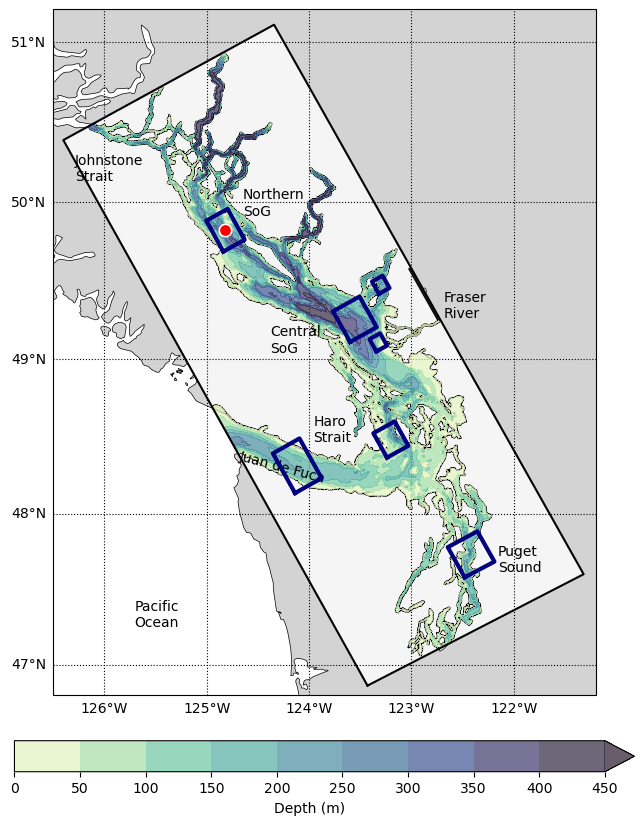

In [7]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cmocean
import cartopy.feature as cfeature
from cartopy import crs, feature
from cartopy.mpl.gridliner import (
    LONGITUDE_FORMATTER,
    LATITUDE_FORMATTER,
)

# ============================================================
# 1. Load model grid / mask
# ============================================================

grid = xr.open_dataset(
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/bathymetry_202108.nc",
    mask_and_scale=False,
)

mask = xr.open_dataset(
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/mesh_mask202108.nc"
)

lon = grid.nav_lon.values
lat = grid.nav_lat.values
bathy = grid.Bathymetry.values

# Surface ocean mask:
# 1 = water, 0 = land
tmask = mask.tmask[0, 0, :, :].values


# ============================================================
# 2. Helper: draw a box defined in NEMO grid-index space
# ============================================================

def plot_grid_box(ax, j0, j1, i0, i1,
                  color="navy", linewidth=3):
    """
    Draw a rectangular region whose bounds are given by
    NEMO grid indices.

    j0, j1 : y-index limits
    i0, i1 : x-index limits
    """

    corners = [
        (j0, i0),
        (j0, i1),
        (j1, i1),
        (j1, i0),
        (j0, i0),
    ]

    box_lon = [lon[j, i] for j, i in corners]
    box_lat = [lat[j, i] for j, i in corners]

    ax.plot(
        box_lon,
        box_lat,
        color=color,
        linewidth=linewidth,
        transform=crs.PlateCarree(),
        zorder=5,
    )


# ============================================================
# 3. Make map
# ============================================================

xlim = [-126.5, -121.2]
ylim = [46.8, 51.2]

fig, ax = plt.subplots(
    figsize=(8, 10),
    subplot_kw={
        "projection": crs.Mercator(
            central_longitude=np.mean(xlim)
        )
    },
)

ax.set_extent(
    [xlim[0], xlim[1], ylim[0], ylim[1]],
    crs=crs.PlateCarree(),
)


# ============================================================
# 4. Geographic coastline / land
# ============================================================

# ax.add_feature(
#     feature.GSHHSFeature(
#         scale="full",
#         edgecolor="black",
#         facecolor="lightgrey",
#     ),
#     zorder=0,
# )

ax.add_feature(
    cfeature.LAND.with_scale("10m"),
    facecolor="lightgrey",
    edgecolor="black",
    linewidth=0.5,
    zorder=0,
)


# ============================================================
# 5. Model domain land/water boundary
# ============================================================

# Similar to the original notebook:
# overlay the model mask to show the actual NEMO model domain.

ax.contourf(
    lon,
    lat,
    tmask,
    levels=[-0.01, 0.01],
    colors=["whitesmoke"],
    transform=crs.PlateCarree(),
    zorder=1,
)

ax.contour(
    lon,
    lat,
    tmask,
    levels=[0.01],
    colors="black",
    linewidths=0.8,
    transform=crs.PlateCarree(),
    zorder=2,
)


# ============================================================
# 6. Draw outer model-domain boundary
# ============================================================

domain_corners = [
    (0, 0),
    (0, -1),
    (-1, -1),
    (-1, 0),
    (0, 0),
]

domain_lon = [lon[j, i] for j, i in domain_corners]
domain_lat = [lat[j, i] for j, i in domain_corners]

ax.plot(
    domain_lon,
    domain_lat,
    "k-",
    linewidth=1.5,
    transform=crs.PlateCarree(),
    zorder=4,
)


# ============================================================
# 7. Bathymetry
# ============================================================

# Mask land cells
bathy_masked = np.ma.masked_where(
    tmask == 0,
    bathy,
)

depth_levels = np.arange(0, 451, 50)

c = ax.contourf(
    lon,
    lat,
    bathy_masked,
    levels=depth_levels,
    cmap=cmocean.cm.deep,
    extend="max",
    alpha=0.7,
    transform=crs.PlateCarree(),
    zorder=3,
)


# ============================================================
# 8. Draw study-region boxes
# ============================================================

# Northern SoG Centre
j, i = 675, 160

ax.scatter(
    lon[j, i],
    lat[j, i],
    s=80,
    color="red",
    edgecolor="white",
    linewidth=1.2,
    marker="o",
    transform=crs.PlateCarree(),
    zorder=10,
)


# These are copied from the original notebook.
# Format:
# name: (j0, j1, i0, i1)

regions = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks": (490, 510, 330, 350),
    "SandHeads": (420, 440, 280, 300),
}

for name, (j0, j1, i0, i1) in regions.items():
    plot_grid_box(
        ax,
        j0, j1,
        i0, i1,
        color="navy",
        linewidth=3,
    )


# ============================================================
# 9. Gridlines
# ============================================================

xlocs = np.arange(
    np.floor(xlim[0]),
    np.ceil(xlim[1]) + 1,
    1,
)

ylocs = np.arange(
    np.floor(ylim[0]),
    np.ceil(ylim[1]) + 1,
    1,
)

gl = ax.gridlines(
    draw_labels=True,
    xlocs=xlocs,
    ylocs=ylocs,
    linestyle=":",
    color="black",
)

gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.top_labels = False
gl.right_labels = False


# ============================================================
# 10. Labels
# ============================================================

# These positions are axis-relative.
ax.text(
    0.15, 0.10,
    "Pacific\nOcean",
    transform=ax.transAxes,
)

ax.text(
    0.82, 0.18,
    "Puget\nSound",
    transform=ax.transAxes,
)

ax.text(
    0.34, 0.31,
    "Juan de Fuca",
    rotation=-15,
    transform=ax.transAxes,
)

ax.text(
    0.40, 0.50,
    "Central\nSoG",
    transform=ax.transAxes,
)

ax.text(
    0.35, 0.70,
    "Northern\nSoG",
    transform=ax.transAxes,
)

ax.text(
    0.04, 0.75,
    "Johnstone\nStrait",
    transform=ax.transAxes,
)

ax.text(
    0.48, 0.37,
    "Haro\nStrait",
    transform=ax.transAxes,
)

ax.text(
    0.72, 0.55,
    "Fraser\nRiver",
    transform=ax.transAxes,
)


# ============================================================
# 11. Colorbar
# ============================================================

cbar = fig.colorbar(
    c,
    ax=ax,
    orientation="horizontal",
    pad=0.06,
    fraction=0.05,
)

cbar.set_label("Depth (m)")


# ============================================================
# 12. Show
# ============================================================

# plt.savefig(
#     "Figure1_StudyAreaMap_clean.png",
#     dpi=300,
#     bbox_inches="tight",
# )

plt.show()

Try Northern SoG now.

### Diatom Response

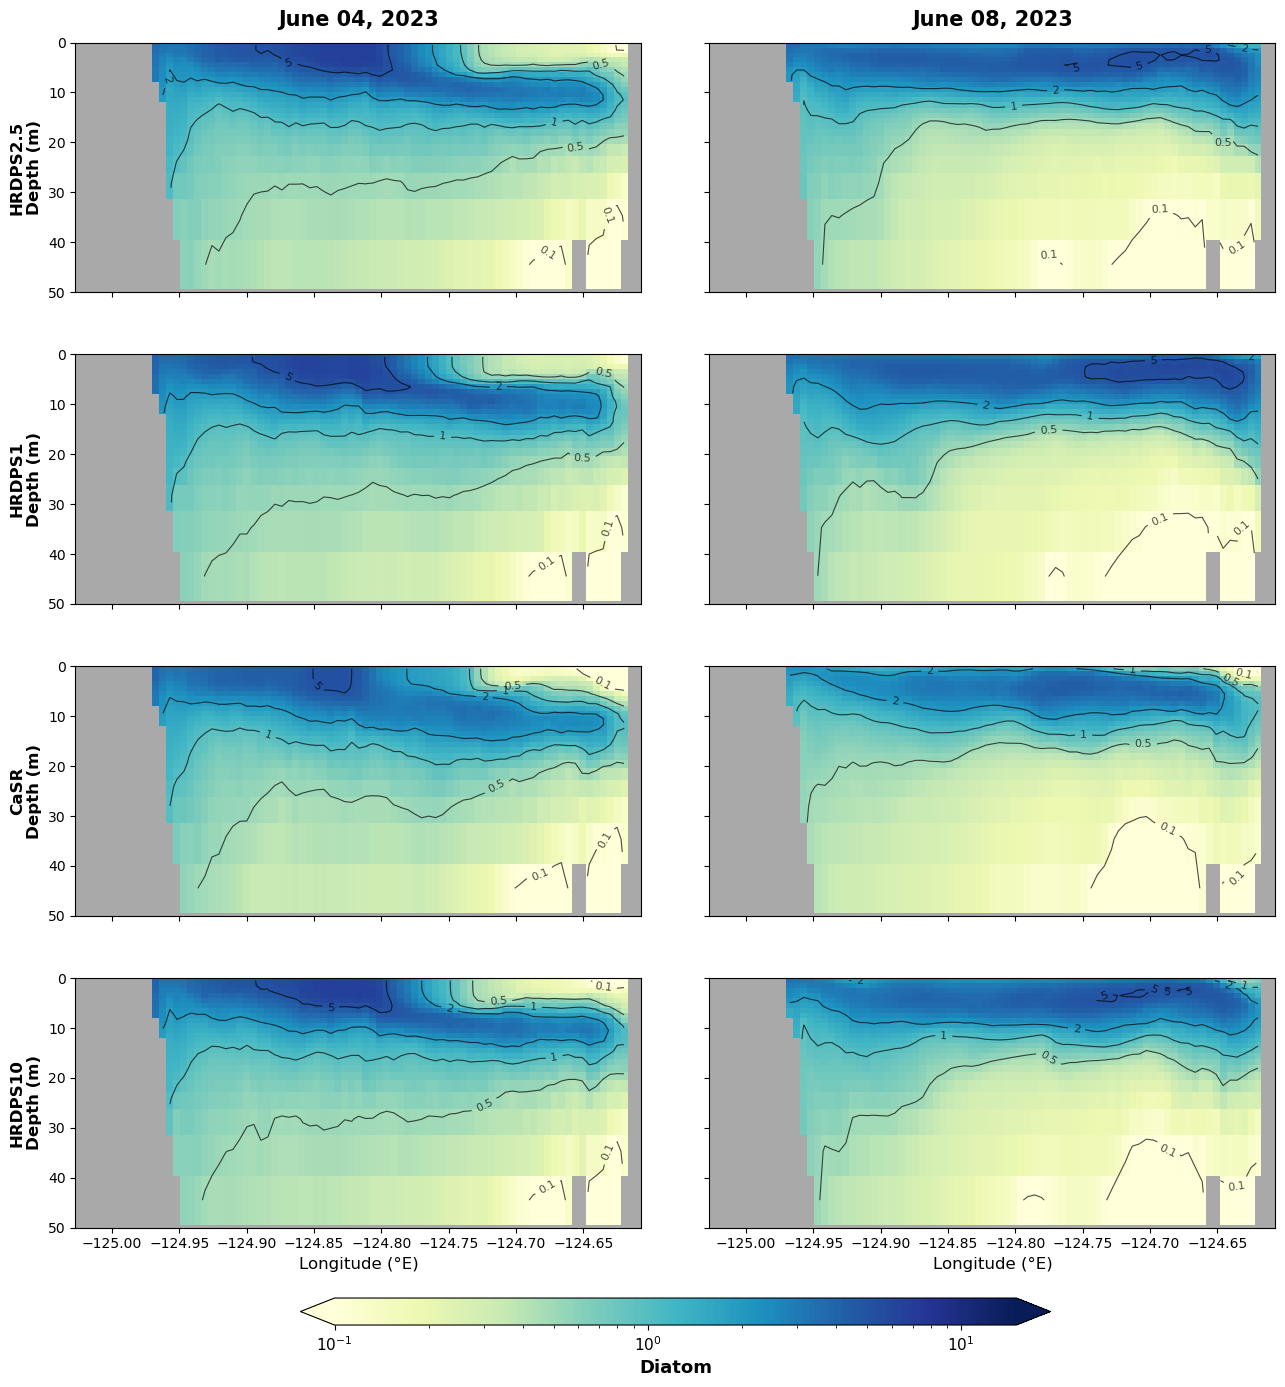

In [12]:

# Bio_Section_Plot_2023_CentralSoG.py
# 2023 June 4 and June 8
# Diatom vertical sections at Central SoG
# 4 experiments x 2 dates

import os
import datetime
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# configure

EXPERIMENTS = {
    "HRDPS2.5": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS1": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/",
        "SalishSea_1d_20230601_20230630"
    ),
    "CaSR": (
        "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS10": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/",
        "SalishSea_1d_20230601_20230630"
    ),
}

DATES = [
    datetime.date(2023, 6, 4),
    datetime.date(2023, 6, 8)
]

# Northern Strait of Georgia
Y_CENTER = 675
X_CENTER = 160

# East-West section
LEFT_OFFSET = 40
RIGHT_OFFSET = 40

DEPTH_LIMIT = 50

# Diatom color scale
VMIN = 0.1
VMAX = 15
CONTOUR_LEVELS = [0.1, 0.5, 1, 2, 5, 10]

CMAP = "YlGnBu"

OUTPUT_FILE = "Diatom_NorthernSoG_June2023_4x2.png"


# load

GRID_FILE = (
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/"
    "bathymetry_202108.nc"
)

MESH_MASK = (
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/"
    "mesh_mask202108.nc"
)

def load_diatom_section(experiment, date_obj):

    base_dir, file_head = EXPERIMENTS[experiment]

    file_path = os.path.join(
        base_dir,
        file_head + "_biol_T.nc"
    )

    if not os.path.exists(file_path):
        print(f"File missing: {file_path}")
        return None

    with nc.Dataset(file_path, "r") as ds:

        # ====================================================
        # Time coordinate
        # ====================================================

        time_var = ds.variables["time_counter"]

        times = nc.num2date(
            time_var[:],
            units=time_var.units,
            calendar=getattr(time_var, "calendar", "standard")
        )

        time_idx = [
            i for i, t in enumerate(times)
            if (t.year, t.month, t.day) ==
               (date_obj.year, date_obj.month, date_obj.day)
        ]

        if len(time_idx) == 0:
            print(f"Date missing: {experiment}, {date_obj}")
            return None

        tidx = time_idx[0]

        # ====================================================
        # Depth
        # ====================================================

        depths = np.asarray(ds.variables["deptht"][:])

        z_indices = np.where(depths <= DEPTH_LIMIT)[0]

        if len(z_indices) == 0:
            raise ValueError("No depth levels within depth limit")

        nz = len(z_indices)

        # ====================================================
        # Load longitude and latitude from original grid
        # ====================================================

        with nc.Dataset(GRID_FILE, "r") as grid:

            lon_2d = np.ma.filled(
                grid.variables["nav_lon"][:],
                np.nan
            )

            lat_2d = np.ma.filled(
                grid.variables["nav_lat"][:],
                np.nan
            )

        # Check horizontal grid dimensions
        if lon_2d.shape != ds.variables["diatoms"].shape[-2:]:
            raise ValueError(
                "Grid dimensions do not match diatom dimensions"
            )

        # ====================================================
        # Section range
        # ====================================================

        nx = lon_2d.shape[1]

        x_start = max(0, X_CENTER - LEFT_OFFSET)
        x_end = min(nx, X_CENTER + RIGHT_OFFSET + 1)

        x_slice = slice(x_start, x_end)

        # ====================================================
        # Extract diatoms
        # ====================================================

        diatom = ds.variables["diatoms"][
            tidx,
            :nz,
            Y_CENTER,
            x_slice
        ]

        diatom = np.ma.masked_invalid(diatom)

        # ====================================================
        # Apply NEMO 3D mesh mask
        # ====================================================

        with nc.Dataset(MESH_MASK, "r") as mesh:

            wet_mask = mesh.variables["tmask"][
                0,
                :nz,
                Y_CENTER,
                x_slice
            ]

            wet_mask = np.ma.filled(wet_mask, 0)

        if wet_mask.shape != diatom.shape:
            raise ValueError(
                f"Mesh mask shape {wet_mask.shape} does not "
                f"match diatom shape {diatom.shape}"
            )

        # Mask land and cells below the seabed
        diatom = np.ma.masked_where(
            wet_mask == 0,
            diatom
        )

        # Mask negative concentrations
        diatom = np.ma.masked_less(diatom, 0)

        # Handle zero concentrations for LogNorm
        diatom = np.ma.where(
            diatom == 0,
            VMIN * 0.01,
            diatom
        )

        # ====================================================
        # Section coordinates
        # ====================================================

        lon_sec = lon_2d[Y_CENTER, x_slice]
        lat_sec = lat_2d[Y_CENTER, x_slice]

        



    return diatom, lon_sec, lat_sec, depths[:nz]


# visualize

def plot_section(ax, diatom, lon, depths):

    ax.set_facecolor("darkgray")

    X, Z = np.meshgrid(lon, depths)

    cf = ax.pcolormesh(
        X,
        Z,
        diatom,
        norm=LogNorm(vmin=VMIN, vmax=VMAX),
        cmap=CMAP,
        shading="auto"
    )

    # Contours
    valid = np.ma.compressed(diatom)

    if valid.size > 0:
        levels = [
            lev for lev in CONTOUR_LEVELS
            if valid.min() < lev < valid.max()
        ]

        if levels:
            cs = ax.contour(
                X,
                Z,
                diatom,
                levels=levels,
                colors="black",
                linewidths=0.8,
                alpha=0.7
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=8,
                fmt="%g"
            )

    # Depth increases downward
    ax.set_ylim(DEPTH_LIMIT, 0)

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    return cf




def main():

    models = list(EXPERIMENTS.keys())

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(15, 15),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.90,
        top=0.92,
        bottom=0.13,
        hspace=0.25,
        wspace=0.12
    )

    cf_last = None

    for row, model in enumerate(models):

        for col, date_obj in enumerate(DATES):

            ax = axes[row, col]

            result = load_diatom_section(
                model,
                date_obj
            )

            if result is None:
                ax.text(
                    0.5, 0.5,
                    "Data Missing",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )
                continue

            diatom, lon, lat, depths = result

            cf = plot_section(
                ax,
                diatom,
                lon,
                depths
            )

            cf_last = cf

            # Column titles
            if row == 0:
                ax.set_title(
                    date_obj.strftime("%B %d, %Y"),
                    fontsize=15,
                    fontweight="bold",
                    pad=12
                )

            # Model labels
            if col == 0:
                ax.set_ylabel(
                    f"{model}\nDepth (m)",
                    fontsize=12,
                    fontweight="bold"
                )

            # Bottom X labels
            if row == 3:
                ax.set_xlabel(
                    "Longitude (°E)",
                    fontsize=12
                )

    # colorbar

    if cf_last is not None:

        cbar_ax = fig.add_axes([
            0.25, 0.065, 0.50, 0.018
        ])

        cbar = fig.colorbar(
            cf_last,
            cax=cbar_ax,
            orientation="horizontal",
            extend="both"
        )

        cbar.set_label(
            "Diatom",
            fontsize=13,
            fontweight="bold"
        )

        cbar.ax.tick_params(labelsize=11)



    plt.show()




if __name__ == "__main__":
    main()

### Salinity

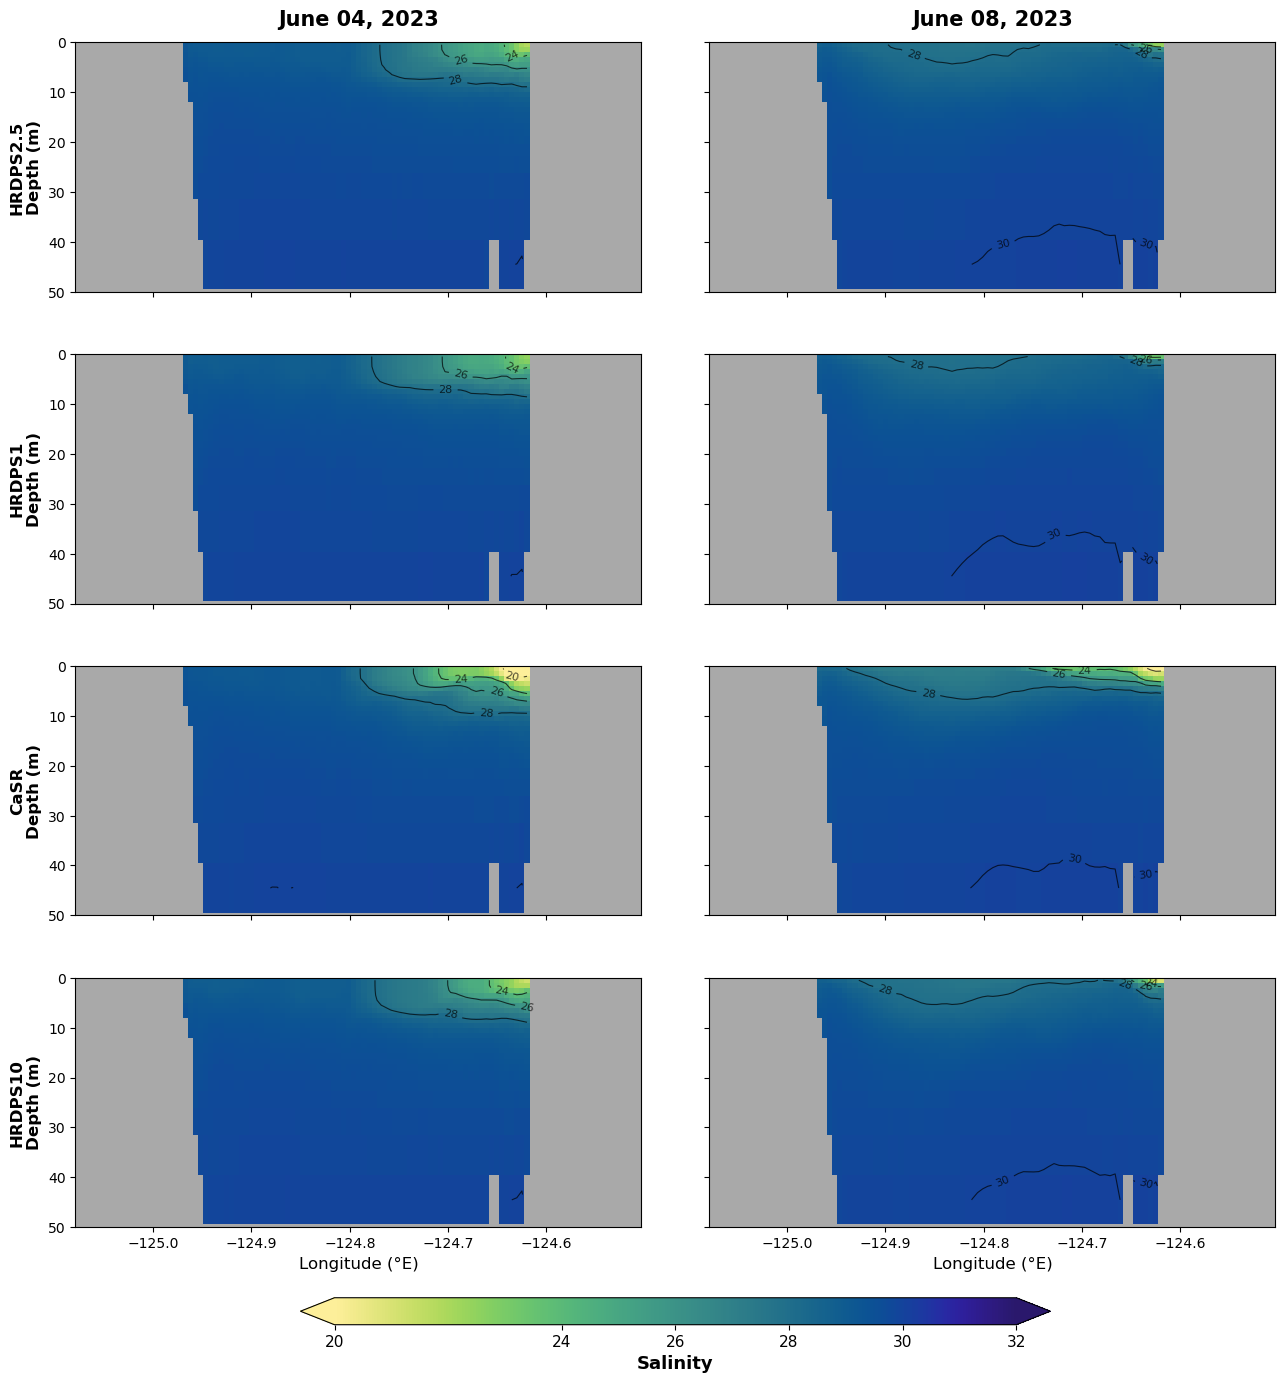

In [14]:
# ============================================================
# Salinity_Section_Plot_2023_NorthernSoG.py
# 2023 June 4 and June 8
# Salinity vertical sections at Northern SoG
# 4 experiments x 2 dates
# ============================================================

import os
import datetime
import netCDF4 as nc
import numpy as np
import matplotlib.pyplot as plt
import cmocean

from matplotlib.colors import Normalize


# ============================================================
# 1. Configure
# ============================================================

EXPERIMENTS = {
    "HRDPS2.5": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps2.5/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS1": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps1/",
        "SalishSea_1d_20230601_20230630"
    ),
    "CaSR": (
        "/ocean/jqiu/results/Flux/flux_00jun23_CaSR/",
        "SalishSea_1d_20230601_20230630"
    ),
    "HRDPS10": (
        "/ocean/jqiu/results/Flux/flux_00jun23_hrdps10/",
        "SalishSea_1d_20230601_20230630"
    ),
}

DATES = [
    datetime.date(2023, 6, 4),
    datetime.date(2023, 6, 8)
]

# Northern Strait of Georgia
Y_CENTER = 675
X_CENTER = 160

# East-West grid section
LEFT_OFFSET = 50
RIGHT_OFFSET = 60

DEPTH_LIMIT = 50

# Salinity color scale
VMIN = 20
VMAX = 32

CONTOUR_LEVELS = [20, 24, 26, 28, 30, 32]

# Reversed salinity colormap:
# Low salinity  = light yellow
# High salinity = dark blue
CMAP = cmocean.cm.haline_r

OUTPUT_FILE = "Salinity_NorthernSoG_June2023_4x2.png"


# ============================================================
# 2. Model grid and mesh mask
# ============================================================

GRID_FILE = (
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/"
    "bathymetry_202108.nc"
)

MESH_MASK = (
    "/ocean/ksuchy/MOAD/NEMO-forcing/grid/"
    "mesh_mask202108.nc"
)


# ============================================================
# 3. Load salinity section
# ============================================================

def load_salinity_section(experiment, date_obj):

    base_dir, file_head = EXPERIMENTS[experiment]

    file_path = os.path.join(
        base_dir,
        file_head + "_grid_T.nc"
    )

    if not os.path.exists(file_path):
        print(f"File missing: {file_path}")
        return None

    with nc.Dataset(file_path, "r") as ds:

        # ====================================================
        # Time coordinate
        # ====================================================

        time_var = ds.variables["time_counter"]

        times = nc.num2date(
            time_var[:],
            units=time_var.units,
            calendar=getattr(time_var, "calendar", "standard")
        )

        # Match target date
        time_idx = [
            i for i, t in enumerate(times)
            if (t.year, t.month, t.day) ==
               (date_obj.year, date_obj.month, date_obj.day)
        ]

        if len(time_idx) == 0:
            print(f"Date missing: {experiment}, {date_obj}")
            return None

        tidx = time_idx[0]

        # ====================================================
        # Depth
        # ====================================================

        depths = np.asarray(ds.variables["deptht"][:])

        z_indices = np.where(depths <= DEPTH_LIMIT)[0]

        if len(z_indices) == 0:
            raise ValueError("No depth levels within depth limit")

        nz = len(z_indices)

        # ====================================================
        # Load longitude and latitude from original grid
        # ====================================================

        with nc.Dataset(GRID_FILE, "r") as grid:

            lon_2d = np.ma.filled(
                grid.variables["nav_lon"][:],
                np.nan
            )

            lat_2d = np.ma.filled(
                grid.variables["nav_lat"][:],
                np.nan
            )

        # Check horizontal grid dimensions
        if lon_2d.shape != ds.variables["vosaline"].shape[-2:]:
            raise ValueError(
                "Grid dimensions do not match salinity dimensions"
            )

        # ====================================================
        # Section range
        # ====================================================

        nx = lon_2d.shape[1]

        x_start = max(0, X_CENTER - LEFT_OFFSET)

        x_end = min(
            nx,
            X_CENTER + RIGHT_OFFSET + 1
        )

        x_slice = slice(x_start, x_end)

        # ====================================================
        # Extract salinity
        # ====================================================

        salinity = ds.variables["vosaline"][
            tidx,
            :nz,
            Y_CENTER,
            x_slice
        ]

        salinity = np.ma.masked_invalid(salinity)

        # ====================================================
        # Apply NEMO 3D mesh mask
        # ====================================================

        with nc.Dataset(MESH_MASK, "r") as mesh:

            wet_mask = mesh.variables["tmask"][
                0,
                :nz,
                Y_CENTER,
                x_slice
            ]

            wet_mask = np.ma.filled(wet_mask, 0)

        # Check shape consistency
        if wet_mask.shape != salinity.shape:

            raise ValueError(
                f"Mesh mask shape {wet_mask.shape} does not "
                f"match salinity shape {salinity.shape}"
            )

        # Mask land and cells below the seabed
        salinity = np.ma.masked_where(
            wet_mask == 0,
            salinity
        )

        # Mask physically invalid negative salinity
        salinity = np.ma.masked_less(
            salinity,
            0
        )

        # ====================================================
        # Section coordinates
        # ====================================================

        lon_sec = lon_2d[Y_CENTER, x_slice]
        lat_sec = lat_2d[Y_CENTER, x_slice]



    return salinity, lon_sec, lat_sec, depths[:nz]


# ============================================================
# 4. Plot salinity section
# ============================================================

def plot_section(ax, salinity, lon, depths):

    ax.set_facecolor("darkgray")

    X, Z = np.meshgrid(lon, depths)

    cf = ax.pcolormesh(
        X,
        Z,
        salinity,
        norm=Normalize(
            vmin=VMIN,
            vmax=VMAX
        ),
        cmap=CMAP,
        shading="auto"
    )

    # ========================================================
    # Salinity contours
    # ========================================================

    valid = np.ma.compressed(salinity)

    if valid.size > 0:

        levels = [
            lev for lev in CONTOUR_LEVELS
            if valid.min() < lev < valid.max()
        ]

        if levels:

            cs = ax.contour(
                X,
                Z,
                salinity,
                levels=levels,
                colors="black",
                linewidths=0.8,
                alpha=0.7
            )

            ax.clabel(
                cs,
                inline=True,
                fontsize=8,
                fmt="%g"
            )

    # Depth increases downward
    ax.set_ylim(DEPTH_LIMIT, 0)

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    return cf


# ============================================================
# 5. Main
# ============================================================

def main():

    models = list(EXPERIMENTS.keys())

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(15, 15),
        sharex=True,
        sharey=True
    )

    fig.subplots_adjust(
        left=0.10,
        right=0.90,
        top=0.92,
        bottom=0.13,
        hspace=0.25,
        wspace=0.12
    )

    cf_last = None

    for row, model in enumerate(models):

        for col, date_obj in enumerate(DATES):

            ax = axes[row, col]

            result = load_salinity_section(
                model,
                date_obj
            )

            if result is None:

                ax.text(
                    0.5, 0.5,
                    "Data Missing",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )

                continue

            salinity, lon, lat, depths = result

            cf = plot_section(
                ax,
                salinity,
                lon,
                depths
            )

            cf_last = cf

            # Column titles
            if row == 0:

                ax.set_title(
                    date_obj.strftime("%B %d, %Y"),
                    fontsize=15,
                    fontweight="bold",
                    pad=12
                )

            # Model labels
            if col == 0:

                ax.set_ylabel(
                    f"{model}\nDepth (m)",
                    fontsize=12,
                    fontweight="bold"
                )

            # Bottom X labels
            if row == 3:

                ax.set_xlabel(
                    "Longitude (°E)",
                    fontsize=12
                )

    # ========================================================
    # 6. Colorbar
    # ========================================================

    if cf_last is not None:

        cbar_ax = fig.add_axes([
            0.25,
            0.065,
            0.50,
            0.018
        ])

        cbar = fig.colorbar(
            cf_last,
            cax=cbar_ax,
            orientation="horizontal",
            ticks=CONTOUR_LEVELS,
            extend="both"
        )

        cbar.set_label(
            "Salinity",
            fontsize=13,
            fontweight="bold"
        )

        cbar.ax.tick_params(
            labelsize=11
        )



    plt.show()


if __name__ == "__main__":
    main()

Significant upwelling and downwelling.

However, it seems that in the boundary grid, CaSR and HRDPS 10 didn't affect Salinity and Diatoms as much as other forcing fields did.

# 